# Dingo tutorial, part 1: training a toy model

In this notebook we train a small neural network with [Dingo](https://dingo-gw.readthedocs.io).
After training, the network returns the posterior distribution of the source parameters for any signal of the kind it has been trained on.

The problem is deliberately simple, so that everything runs on a laptop in a few minutes, without a GPU.

* The source is a binary black hole, like those regularly observed by the LIGO and Virgo detectors.
  We use three detectors: LIGO Hanford (H1), LIGO Livingston (L1) and Virgo (V1).
* Only **two parameters** are unknown: the detector-frame chirp mass $\mathcal{M}_d$ and the luminosity distance $D_L$.
* All other parameters (mass ratio, spins, inclination, sky position, arrival time, ...) are fixed to known values.

The steps are:

1. generate a data set of waveforms;
2. describe the detector noise;
3. train the network;
4. look at the learning curve.

**Requirements.** Install Dingo with `pip install dingo-gw`. This tutorial was written for Dingo version 0.10.

**Run time.** About 10 minutes in total on a laptop. Most of it is the training in step 3.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import yaml

# The folder ../figures contains a small module with the plotting style used in the book
import sys
sys.path.append("../figures")
from gwr_style import COLORS, TEXTWIDTH, save_figure, use_book_style

# Folders where Dingo will write its files
os.makedirs("training_data", exist_ok=True)
os.makedirs("training", exist_ok=True)

## Step 1: the waveform data set

Dingo learns from examples. The first ingredient is a large set of waveforms, each computed for different source parameters.

The data set is described by the settings file `waveform_dataset_settings.yaml`. Let us read it.

In [2]:
with open("waveform_dataset_settings.yaml") as file:
    print(file.read())

# Settings of the waveform data set for the toy model.
#
# The source is a binary black hole. Only the chirp mass changes from one waveform
# to the next. All the other intrinsic parameters are fixed to a single value.

# Frequencies at which the waveforms are computed.
domain:
  type: UniformFrequencyDomain
  f_min: 20.0
  f_max: 512.0
  delta_f: 0.25    # frequency spacing in Hz; 0.25 Hz corresponds to 4 s of data

# Waveform model.
waveform_generator:
  approximant: IMRPhenomD
  f_ref: 20.0      # reference frequency in Hz

# Priors of the intrinsic parameters, written as Bilby priors.
# A parameter followed by a single number is fixed to that value.
intrinsic_prior:
  mass_1: bilby.core.prior.Constraint(minimum=10.0, maximum=80.0)
  mass_2: bilby.core.prior.Constraint(minimum=10.0, maximum=80.0)
  chirp_mass: bilby.core.prior.Uniform(minimum=25.0, maximum=35.0)
  mass_ratio: 0.8
  chi_1: 0.0
  chi_2: 0.0
  theta_jn: 0.5
  phase: 0.0
  luminosity_distance: 100.0   # Mpc, reference v

The file has four blocks.

* `domain`: the frequencies at which the waveforms are computed. A spacing of 0.25 Hz corresponds to 4 seconds of data.
* `waveform_generator`: the waveform model. `IMRPhenomD` is a fast model for binaries with spins aligned with the orbit.
* `intrinsic_prior`: the prior of the parameters that determine the shape of the waveform.
  The chirp mass is drawn uniformly between 25 and 35 solar masses. A parameter followed by a single number is fixed to that value.
* `num_samples` and `compression`: how many waveforms to generate, and how to store them compactly (see below).

The command `dingo_generate_dataset` reads the settings and generates the waveforms.
(A line that starts with `!` runs a command in the terminal.)

In [3]:
if not os.path.exists("training_data/waveform_dataset.hdf5"):
    !dingo_generate_dataset --settings waveform_dataset_settings.yaml --out_file training_data/waveform_dataset.hdf5 --num_processes 2
else:
    print("The waveform data set already exists: nothing to do.")

The waveform data set already exists: nothing to do.


### Checking the compression

A waveform is stored as about 2000 complex numbers, one for each frequency.
Dingo can compress it with a *singular value decomposition* (SVD): each waveform is written as a combination of a few basis waveforms.
Here we keep 50 basis elements, so each waveform is described by 50 numbers instead of 2000.

The compression is not exact, and we must check that the error is small.
The error is measured by the *mismatch* between the original and the reconstructed waveform: 0 means identical.
The command `dingo_ls` prints the settings of the data set and, at the end, a summary of the mismatches.

In [4]:
!dingo_ls training_data/waveform_dataset.hdf5

Loading dataset from training_data/waveform_dataset.hdf5.
Omitting data keys ['polarizations'].
Dingo version: dingo=0.10.3

Waveform dataset

Dataset size: 20000

Settings
--------
domain:
  type: UniformFrequencyDomain
  f_min: 20.0
  f_max: 512.0
  delta_f: 0.25
waveform_generator:
  approximant: IMRPhenomD
  f_ref: 20.0
intrinsic_prior:
  mass_1: bilby.core.prior.Constraint(minimum=10.0, maximum=80.0, name='mass_1')
  mass_2: bilby.core.prior.Constraint(minimum=10.0, maximum=80.0, name='mass_2')
  chirp_mass: bilby.core.prior.Uniform(minimum=25.0, maximum=35.0, name='chirp_mass')
  mass_ratio: 0.8
  chi_1: 0.0
  chi_2: 0.0
  theta_jn: 0.5
  phase: 0.0
  luminosity_distance: 100.0
  geocent_time: 0.0
num_samples: 20000
compression:
  svd:
    size: 50
    num_training_samples: 2000
    num_validation_samples: 500


SVD validation summary:
---------------------------
n = 50
  Mean mismatch = 2.399536125352597e-14
  Standard deviation = 2.0248985742528093e-14
  Max mismatch = 1.115774

The mismatches are tiny (much smaller than $10^{-4}$), so the compression is safe.
In harder problems, with more parameters, more basis elements are needed.

## Step 2: the detector noise

During training, noise is added to every waveform. Dingo needs to know the noise level at each frequency.
This is the *amplitude spectral density* (ASD) of each detector.

For real detectors, the command `dingo_generate_asd_dataset` downloads public data and estimates the ASD from them.
Here we take a shortcut that needs no download: we use sensitivity curves that are distributed with the Bilby package.

* For the two LIGO detectors we use the curve of the fourth LIGO-Virgo-KAGRA observing run (O4).
* For Virgo we use the design curve of Advanced Virgo.

The cell below reads the curve and saves it in the format that Dingo expects.

In [5]:
from bilby.gw.detector import PowerSpectralDensity
from dingo.gw.domains import build_domain
from dingo.gw.noise.asd_dataset import ASDDataset

# Build the same frequency grid used for the waveforms
with open("waveform_dataset_settings.yaml") as file:
    settings = yaml.safe_load(file)
domain = build_domain(settings["domain"])
frequencies = domain()  # all frequencies, from 0 Hz to f_max

# Sensitivity curve of each detector (files distributed with Bilby)
noise_files = {
    "H1": "aLIGO_O4_high_asd.txt",  # LIGO Hanford
    "L1": "aLIGO_O4_high_asd.txt",  # LIGO Livingston
    "V1": "AdV_asd.txt",            # Virgo
}

asds = {}
for detector, noise_file in noise_files.items():
    # Read the curve and evaluate it on our frequencies
    noise_curve = PowerSpectralDensity(asd_file=noise_file)
    asd = noise_curve.get_amplitude_spectral_density_array(frequencies)
    # The curve is not defined at very low frequencies. Those frequencies are below f_min = 20 Hz
    # and are never used, so we simply put a placeholder value there.
    asd[~np.isfinite(asd)] = 1.0
    asds[detector] = asd

# Save the curves in Dingo's format
asd_dataset = ASDDataset(
    dictionary={
        "settings": {"domain_dict": domain.domain_dict},
        "asds": {detector: np.array([asds[detector]]) for detector in asds},
        "gps_times": {detector: np.array([0.0]) for detector in asds},
    }
)
asd_dataset.to_file("training_data/asd_dataset.hdf5")

/usr/local/lib/python3.13/site-packages/dingo/gw/__init__.py:3: UserWarning: Wswiglal-redir-stdio:
----------------------------------------------------------------
SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
----------------------------------------------------------------

  import lal


Saving dataset to training_data/asd_dataset.hdf5


A quick look at the noise curves. The detectors are most sensitive around 100-200 Hz.

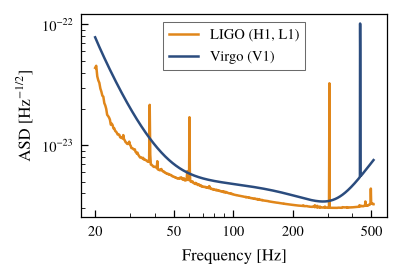

In [6]:
use_book_style()  # make sure the style of the book is active
fig, ax = plt.subplots(figsize=(0.6 * TEXTWIDTH, 0.4 * TEXTWIDTH))
in_band = frequencies >= 20
ax.loglog(frequencies[in_band], asds["H1"][in_band], color=COLORS["orange"], label="LIGO (H1, L1)")
ax.loglog(frequencies[in_band], asds["V1"][in_band], color=COLORS["blue"], label="Virgo (V1)")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel(r"ASD [Hz$^{-1/2}$]")
# Choose the tick labels of the frequency axis by hand, so that they do not overlap
ax.set_xticks([20, 50, 100, 200, 500])
ax.set_xticklabels(["20", "50", "100", "200", "500"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend()
plt.show()

## Step 3: training

The training is described by a second settings file, `train_settings.yaml`.

In [7]:
with open("train_settings.yaml") as file:
    print(file.read())

# Training settings for the toy model.

# ---------------------------------------------------------------------------
# Data: detectors, extrinsic parameters, and what the network must learn.
# ---------------------------------------------------------------------------
data:
  waveform_dataset_path: training_data/waveform_dataset.hdf5
  train_fraction: 0.95       # 95% of the waveforms for training, 5% for testing
  detectors: [H1, L1, V1]    # LIGO Hanford, LIGO Livingston and Virgo
  # Priors of the extrinsic parameters. These are drawn at random during training.
  # Here only the luminosity distance is free; the others are fixed.
  extrinsic_prior:
    luminosity_distance: bilby.core.prior.Uniform(minimum=1000.0, maximum=3000.0)
    dec: 0.3
    ra: 1.0
    psi: 0.5
    geocent_time: 0.0
  ref_time: 1126259462.391   # GPS time that fixes the orientation of the Earth
  # Parameters that the network learns to infer.
  inference_parameters: [chirp_mass, luminosity_distance]

# --------

The file has four blocks.

* `data`: which detectors to use, and the prior of the *extrinsic* parameters.
  These parameters describe where the source is and how it is oriented with respect to the detectors.
  Here only the luminosity distance is free (uniform between 1000 and 3000 Mpc); the others are fixed.
  The entry `inference_parameters` lists what the network must learn: chirp mass and distance.
* `model`: the neural network. It has two parts.
  The *embedding network* compresses the data into a few numbers (here 32).
  The *normalizing flow* turns these numbers into a probability distribution for the parameters.
  Both are much smaller than in a real analysis.
* `training`: how to train. An *epoch* is one pass through all the waveforms.
  The *learning rate* `lr` sets how much the network changes at each step. The `scheduler` decreases it gradually to zero.
  The `batch_size` is the number of waveforms used at each step.
* `local`: settings of your computer. `device: cpu` means that no GPU is used.

At every step Dingo takes waveforms from the data set, draws a random distance, projects them onto the three detectors and adds random noise.
So the network never sees the same data twice.

The next cell starts the training. **It takes about 10 minutes on two CPU cores.**
Dingo prints the progress of each epoch.

In [8]:
if not os.path.exists("training/model_stage_0.pt"):
    !dingo_train --settings_file train_settings.yaml --train_dir training
else:
    print("A trained model already exists in the folder 'training': nothing to do.")

Beginning new training run.
Loading dataset from training_data/waveform_dataset.hdf5.
Omitting data keys ['polarizations'].

Building SVD for initialization of embedding network.
Setting train transforms.
Omitting 
	AddWhiteNoiseComplex
	RepackageStrainsAndASDS
	SelectStandardizeRepackageParameters
	UnpackDict
	CropMaskStrainRandom


Loading dataset from training_data/asd_dataset.hdf5.
Calculating new parameter standardizations.
Generating waveforms for embedding network SVD initialization.


...done. This took 1 s.
Generating SVD basis for ifo:


...H1 done.


...L1 done.


...V1 done.
...this took 5 s.
Testing SVD basis matrices.
...H1:


... (4,769 outputs left out)

		Time Dataloader: 0.065 (0.067)		Time Network: 0.018 (0.018)


Test Epoch: 30 [1000/1000 (100%)]		Loss: -4.232 (-4.184)		Time Dataloader: 0.053 (0.065)		Time Network: 0.017 (0.018)
Done. This took  0: 1 min.
Saving model to training/model_latest.pt. 

Done.
Copy model to checkpoint training/model_030.pt. Done.
Finished training epoch 30.

Stop run: Epoch limit of 30 per run reached.
Stop run: Total epoch limit of 30 reached.
Training stage complete. Saving to training/model_stage_0.pt.


Local runtime limits reached. Ending program.
All training stages complete.


When the training ends, the folder `training` contains:

* `model_stage_0.pt`: the trained network;
* `history.txt`: the value of the loss after each epoch.

In [9]:
print(sorted(os.listdir("training")))

['history.txt', 'local_settings.yaml', 'model_010.pt', 'model_020.pt', 'model_030.pt', 'model_latest.pt', 'model_stage_0.pt', 'svd_H1.hdf5', 'svd_L1.hdf5', 'svd_V1.hdf5']


## Step 4: the learning curve

The *loss* is the number that the training tries to make as small as possible. It measures how badly the network describes the posterior.
Dingo computes it on two sets of waveforms:

* the **training set** (95% of the waveforms), used to adjust the network;
* the **test set** (the remaining 5%), never used to adjust the network.

The file `history.txt` has four columns: epoch, training loss, test loss, learning rate.

Figure saved to output/fig_learning_curves.pdf


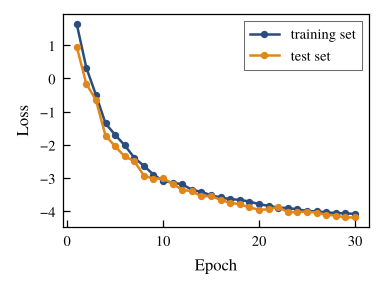

In [10]:
epoch, train_loss, test_loss, learning_rate = np.loadtxt("training/history.txt", unpack=True)

use_book_style()  # make sure the style of the book is active
fig, ax = plt.subplots(figsize=(0.6 * TEXTWIDTH, 0.42 * TEXTWIDTH))
ax.plot(epoch, train_loss, "o-", ms=2.5, color=COLORS["blue"], label="training set")  # one marker per epoch
ax.plot(epoch, test_loss, "o-", ms=2.5, color=COLORS["orange"], label="test set")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
save_figure(fig, "fig_learning_curves.pdf")
plt.show()

Both curves decrease quickly at the beginning and then flatten. They stay close to each other.
This is what a healthy training looks like.

The value of the loss has no absolute meaning, and it can be negative.
What matters is its evolution.

The network is now ready. In part 2 we use it to analyse a simulated signal.